In [17]:
import os
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms, models
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix, classification_report, precision_recall_fscore_support

device = torch.device('mps') if torch.backends.mps.is_available() else torch.device('cpu')
print(f"✅ تم التجهيز على: {device}")


✅ تم التجهيز على: cpu


In [18]:
# 1. تحويلات التدريب (تعزيز قوي لمنع الحفظ)
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(40), # تدوير زاوية كبيرة
    transforms.ColorJitter(brightness=0.3, contrast=0.3),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

# 2. تحويلات الاختبار (إضافة تحديات لكسر الدقة الوهمية)
test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.GaussianBlur(kernel_size=(5, 5), sigma=(0.1, 2.0)), # تحدي للموديل
    transforms.ColorJitter(brightness=0.4), # تغيير إضاءة الاختبار
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])


In [19]:
data_dir = "/Users/rwan/Desktop/archive-8"
full_dataset = datasets.ImageFolder(root=data_dir)

# التقسيم الرقمي
train_size = int(0.70 * len(full_dataset))
test_size = int(0.20 * len(full_dataset))
val_size = len(full_dataset) - train_size - test_size

train_raw, test_raw, val_raw = random_split(full_dataset, [train_size, test_size, val_size])

# ربط كل قسم بتحويلاته الخاصة (خطوة مهمة جداً)
class TransformedDataset(torch.utils.data.Dataset):
    def __init__(self, subset, transform=None):
        self.subset = subset
        self.transform = transform
    def __getitem__(self, index):
        x, y = self.subset[index]
        if self.transform: x = self.transform(x)
        return x, y
    def __len__(self): return len(self.subset)

train_loader = DataLoader(TransformedDataset(train_raw, train_transform), batch_size=32, shuffle=True)
test_loader = DataLoader(TransformedDataset(test_raw, test_transform), batch_size=32, shuffle=False)
val_loader = DataLoader(TransformedDataset(val_raw, test_transform), batch_size=32, shuffle=False)

print(f"📊 التقسيم النهائي: تدريب {train_size} | اختبار {test_size} | تحقق {val_size}")


📊 التقسيم النهائي: تدريب 476 | اختبار 136 | تحقق 69


In [20]:
model = models.resnet34(pretrained=True)
num_ftrs = model.fc.in_features

# إضافة Dropout بنسبة 0.7 لضمان عدم الحفظ
model.fc = nn.Sequential(
    nn.Linear(num_ftrs, 512),
    nn.ReLU(),
    nn.Dropout(0.7), 
    nn.Linear(512, 2)
)
model.to(device)

# المحسن مع "عقوبة" Weight Decay لمنع تعقيد الأوزان
optimizer = optim.Adam(model.parameters(), lr=0.0001, weight_decay=0.01)
criterion = nn.CrossEntropyLoss()


/Users/rwan/opt/anaconda3/lib/python3.12/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/Users/rwan/opt/anaconda3/lib/python3.12/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet34_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet34_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


In [21]:
epochs = 10
train_losses, val_losses = [], []

for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    for imgs, lbls in tqdm(train_loader, desc=f"Epoch {epoch+1}"):
        imgs, lbls = imgs.to(device), lbls.to(device)
        optimizer.zero_grad()
        loss = criterion(model(imgs), lbls)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
    
    # حساب خسارة التحقق
    model.eval()
    v_loss = 0.0
    with torch.no_grad():
        for imgs, lbls in val_loader:
            v_loss += criterion(model(imgs.to(device)), lbls.to(device)).item()
    
    train_losses.append(running_loss/len(train_loader))
    val_losses.append(v_loss/len(val_loader))
    print(f"📉 Loss: Train={train_losses[-1]:.4f}, Val={val_losses[-1]:.4f}")


Epoch 1:   0%|          | 0/15 [00:00<?, ?it/s]

📉 Loss: Train=0.3773, Val=0.2763


Epoch 2:   0%|          | 0/15 [00:00<?, ?it/s]

📉 Loss: Train=0.0823, Val=0.3211


Epoch 3:   0%|          | 0/15 [00:00<?, ?it/s]

📉 Loss: Train=0.0828, Val=0.3611


... (10 outputs left out)

Epoch 9:   0%|          | 0/15 [00:00<?, ?it/s]

📉 Loss: Train=0.0367, Val=0.3373


Epoch 10:   0%|          | 0/15 [00:00<?, ?it/s]

📉 Loss: Train=0.0334, Val=0.7329



📝 الجدول النهائي للمقاييس المئوية:


,المقياس,Precision %,Recall %,F1-Score %
0,Normal Road,84.15,100.0,91.39
1,Pothole Road,100.00,80.6,89.26


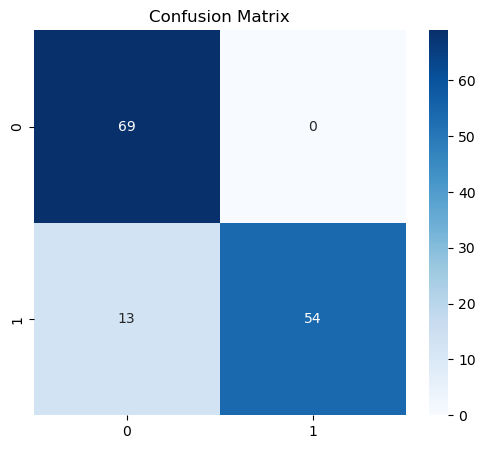

In [22]:
def show_final_report():
    model.eval()
    y_true, y_pred = [], []
    with torch.no_grad():
        for imgs, lbls in test_loader:
            outputs = model(imgs.to(device))
            _, predicted = torch.max(outputs, 1)
            y_true.extend(lbls.numpy())
            y_pred.extend(predicted.cpu().numpy())
    
    # حساب المقاييس
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, average=None)
    
    report_data = {
        'المقياس': ['Normal Road', 'Pothole Road'],
        'Precision %': [p[0]*100, p[1]*100],
        'Recall %': [r[0]*100, r[1]*100],
        'F1-Score %': [f[0]*100, f[1]*100]
    }
    
    df = pd.DataFrame(report_data).round(2)
    print("\n📝 الجدول النهائي للمقاييس المئوية:")
    display(df)
    
    # رسم مصفوفة الارتباك
    plt.figure(figsize=(6,5))
    sns.heatmap(confusion_matrix(y_true, y_pred), annot=True, fmt='d', cmap='Blues')
    plt.title("Confusion Matrix")
    plt.show()

show_final_report()


In [23]:
from sklearn.metrics import precision_recall_fscore_support
import pandas as pd

def get_metrics_table(model, loader):
    model.eval()
    all_preds = []
    all_labels = []
    
    with torch.no_grad():
        for imgs, lbls in loader:
            imgs = imgs.to(device)
            outputs = model(imgs)
            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(lbls.numpy())
    
    # حساب المقاييس لكل صنف (Precision, Recall, F1)
    precision, recall, f1, _ = precision_recall_fscore_support(all_labels, all_preds, average=None)
    
    # حساب المتوسط العام (Macro Average)
    precision_avg, recall_avg, f1_avg, _ = precision_recall_fscore_support(all_labels, all_preds, average='macro')
    
    # إنشاء الجدول وتنسيق البيانات كنسب مئوية
    metrics_data = {
        'الصنف (Class)': ['طريق سليم (Normal)', 'حفرة (Pothole)', 'المتوسط العام (Average)'],
        'الدقة المحددة (Precision) %': [precision[0]*100, precision[1]*100, precision_avg*100],
        'الاستدعاء (Recall) %': [recall[0]*100, recall[1]*100, recall_avg*100],
        'مقياس (F1-Score) %': [f1[0]*100, f1[1]*100, f1_avg*100]
    }
    
    df_metrics = pd.DataFrame(metrics_data)
    
    # تنسيق الأرقام لتظهر بمنزلتين عشريتين فقط
    return df_metrics.round(2)

# تشغيل واستخراج الجدول بناءً على بيانات الاختبار
final_report_df = get_metrics_table(model, test_loader)

# عرض الجدول بشكل أنيق في Jupyter
display(final_report_df)


,الصنف (Class),الدقة المحددة (Precision) %,الاستدعاء (Recall) %,مقياس (F1-Score) %
0,طريق سليم (Normal),82.93,98.55,90.07
1,حفرة (Pothole),98.15,79.10,87.60
2,المتوسط العام (Average),90.54,88.83,88.83


In [24]:
# بعد انتهاء التدريب وظهور النتائج النهائية
# تأكدي أن الموديل هو الذي تم تدريبه للتو
torch.save(model.state_dict(), 'pothole_classifier_model.pth')
print("✅ تم حفظ الموديل بنجاح باسم: pothole_classifier_model.pth")



✅ تم حفظ الموديل بنجاح باسم: pothole_classifier_model.pth


In [1]:
!pip install ultralytics



[notice] A new release of pip is available: 25.2 -> 26.0
[notice] To update, run: pip install --upgrade pip


In [2]:
from ultralytics import YOLO
import os

# 1. تجهيز ملف الإعدادات yaml برمجياً (أسهل لكِ)
yaml_content = f"""
train: /Users/rwan/Desktop/Pothole_Segmentation_YOLOv8/train/images
val: /Users/rwan/Desktop/Pothole_Segmentation_YOLOv8/valid/images

nc: 1
names: ['pothole']
"""

with open('pothole_data.yaml', 'w') as f:
    f.write(yaml_content)

# 2. تحميل الموديل (النسخة الصغيرة لتعمل بسرعة على الماك)
model = YOLO('yolov8n-seg.pt') 

# 3. بدء التدريب (هنا الموديل سيتعلم كيف "يرسم" حول الحفرة والشقوق)
# أضفت لكِ 'mps' لتسريع التدريب باستخدام معالج الماك
model.train(
    data='pothole_data.yaml', 
    epochs=30, 
    imgsz=640, 
    device='mps'
)


New https://pypi.org/project/ultralytics/8.4.9 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.7 🚀 Python-3.12.2 torch-2.2.2 CPU (Intel Core i5-1038NG7 2.00GHz)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=pothole_data.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n-seg.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train2, nbs=64, nms=False, opset=None,

ultralytics.utils.metrics.SegmentMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x124f8dc10>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)', 'Precision-Recall(M)', 'F1-Confidence(M)', 'Precision-Confidence(M)', 'Recall-Confidence(M)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    

In [3]:
# هذا الكود سيحسب لكِ الدقة النهائية بدقة عالية
metrics = model.val() 
print(f"الدقة العامة (mAP50): {metrics.seg.map50 * 100:.2f}%")


Ultralytics 8.4.7 🚀 Python-3.12.2 torch-2.2.2 CPU (Intel Core i5-1038NG7 2.00GHz)
YOLOv8n-seg summary (fused): 86 layers, 3,258,259 parameters, 0 gradients, 11.3 GFLOPs
val: Fast image access ✅ (ping: 0.3±0.2 ms, read: 125.7±38.1 MB/s, size: 76.5 KB)
val: Scanning /Users/rwan/Desktop/Pothole_Segmentation_YOLOv8/valid/labels.cache... 60 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 60/60 895.6Kit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 4.3s/it 17.4s7.0ss
                   all         60        201       0.67      0.706      0.746      0.453      0.667      0.706      0.748      0.445
Speed: 7.3ms preprocess, 208.5ms inference, 0.0ms loss, 41.8ms postprocess per image
Results saved to /Users/rwan/runs/segment/val
الدقة العامة (mAP50): 74.83%


In [4]:
# كود استخراج أنواع العيوب التي تدرب عليها الموديل
class_names = model.names
print("--- قائمة الأنواع التي يتعرف عليها عين حائل ---")
for index, name in class_names.items():
    print(f"الصنف رقم {index}: {name}")

# لإظهار عدد الأصناف الكلي
print(f"\nعدد الأصناف الكلي: {len(class_names)}")


--- قائمة الأنواع التي يتعرف عليها عين حائل ---
الصنف رقم 0: pothole

عدد الأصناف الكلي: 1


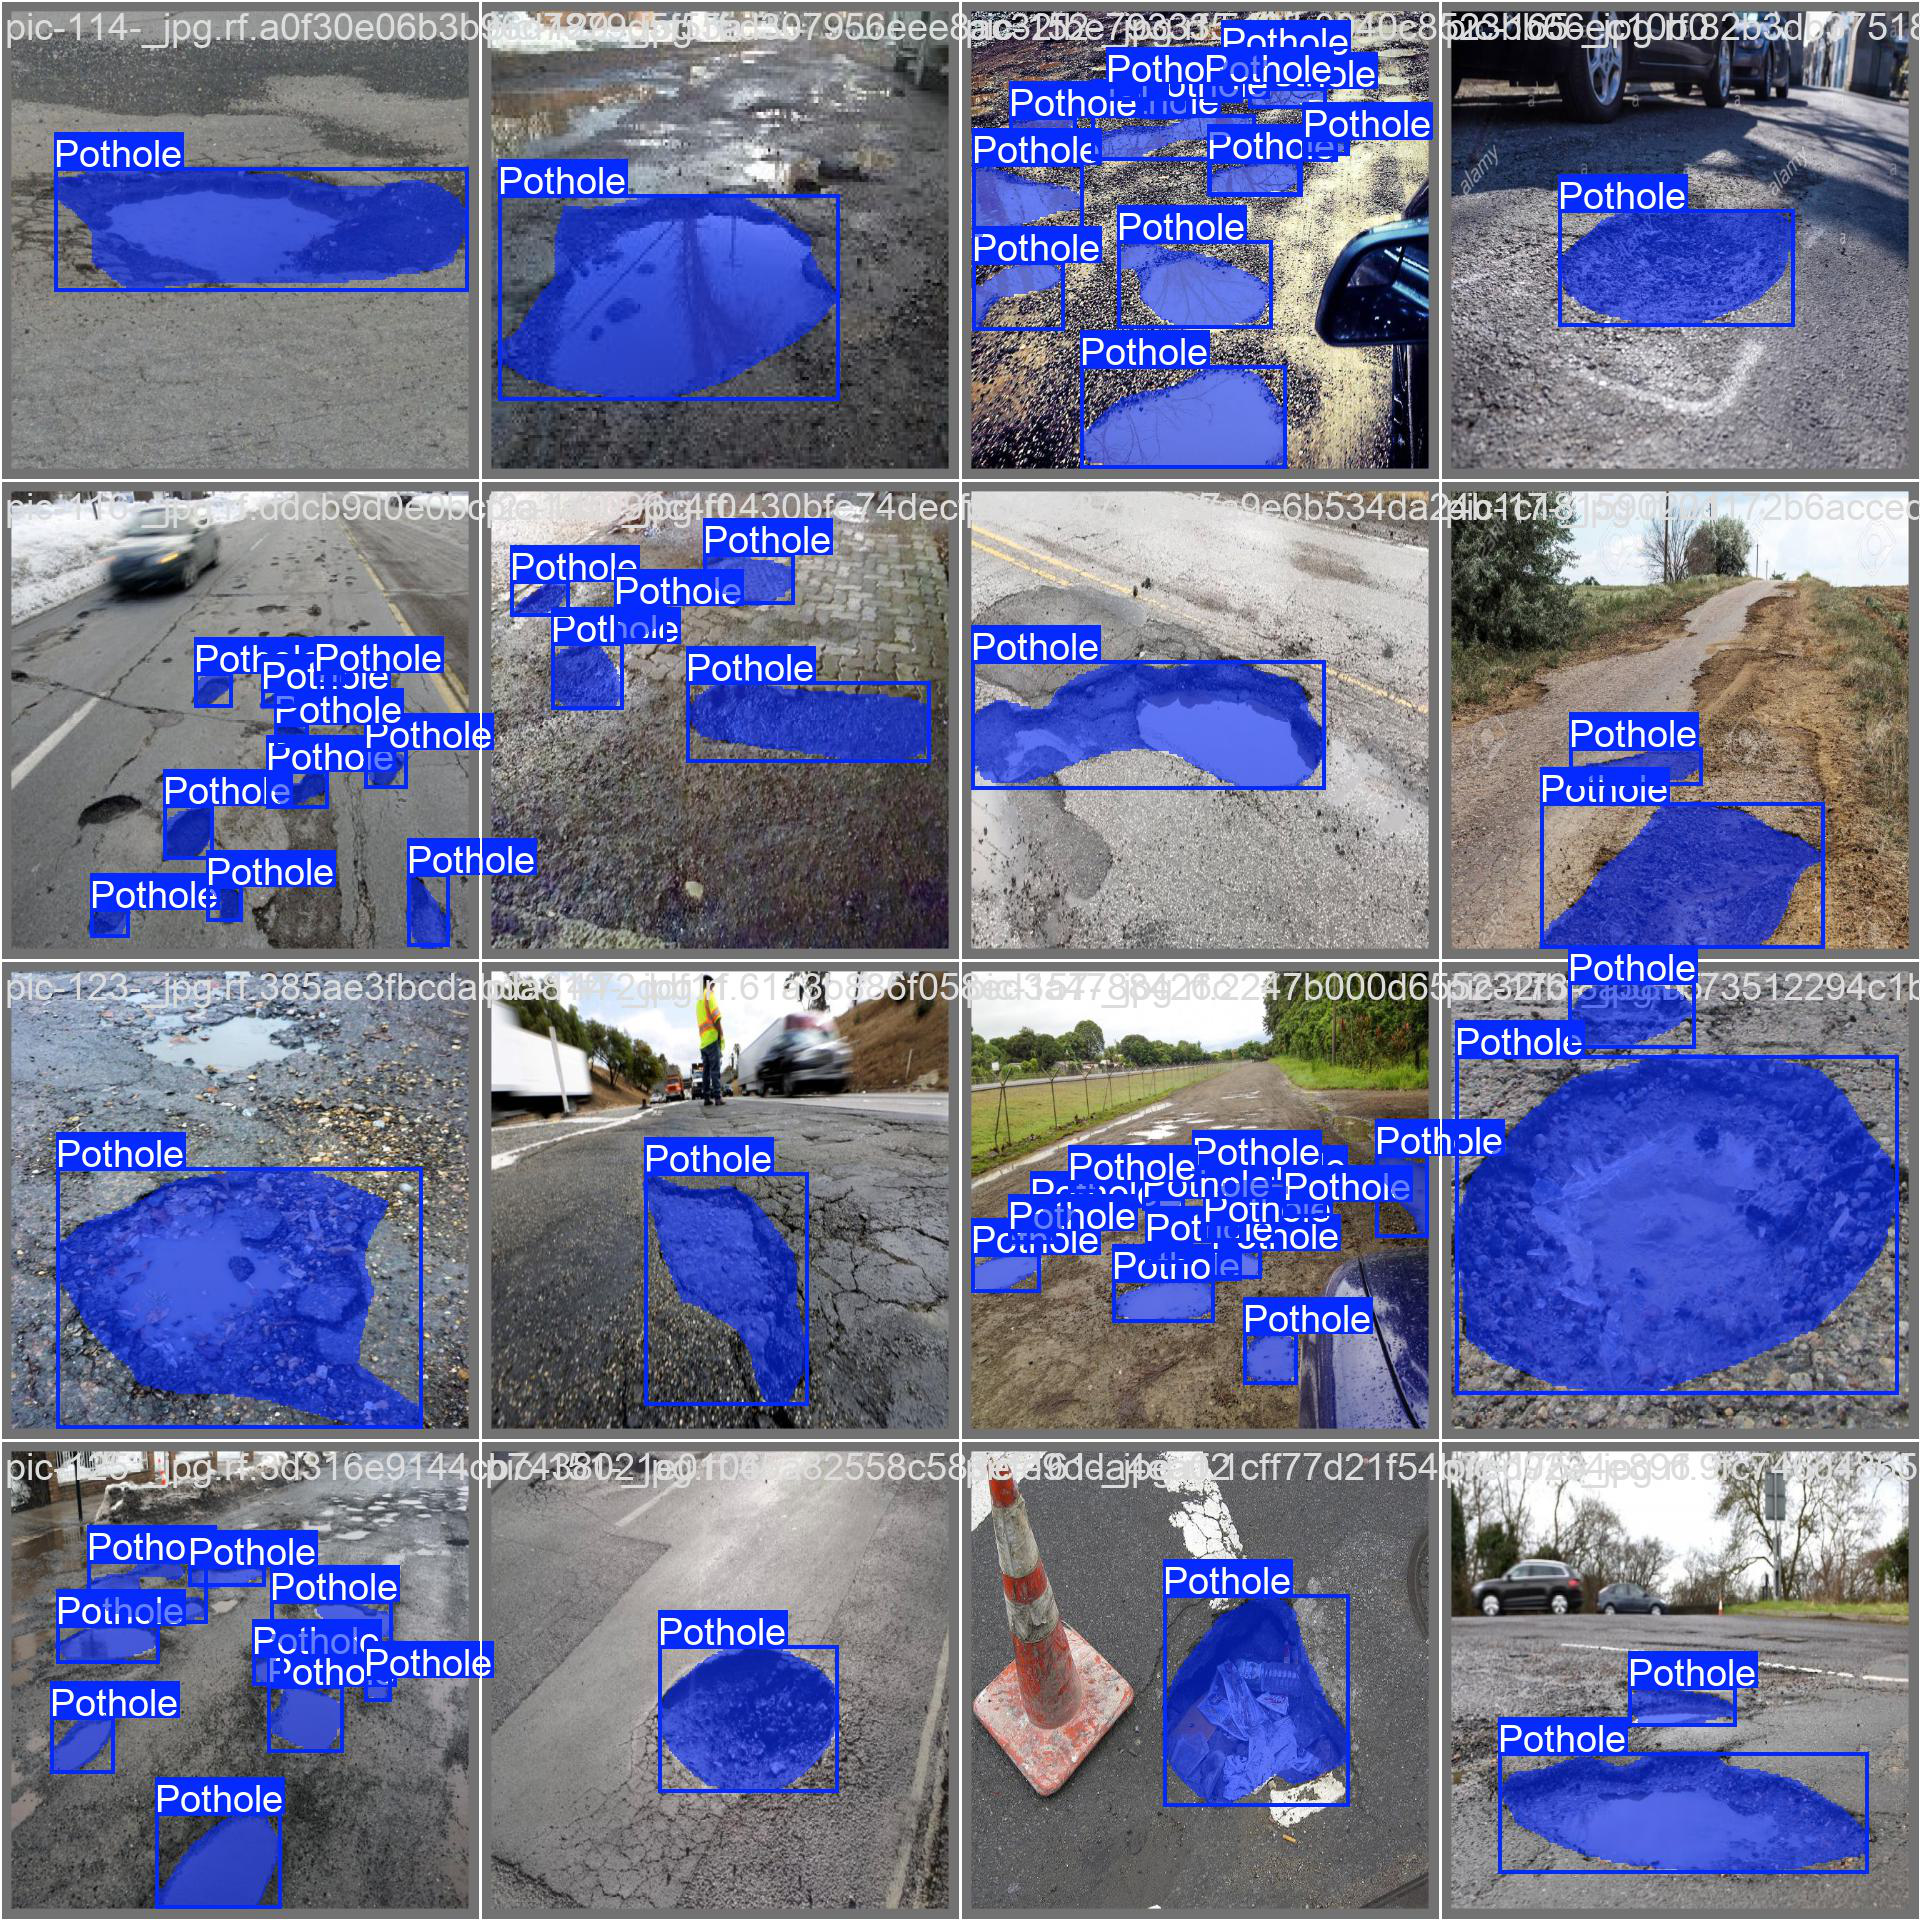

In [5]:
# إظهار عينة من صور التدريب مع "الماسك" الملون
import matplotlib.pyplot as plt
from PIL import Image

# ابحثي عن صورة النتائج التي رسمها يولو تلقائياً
results_image = 'runs/segment/train/val_batch0_labels.jpg'
if os.path.exists(results_image):
    display(Image.open(results_image))
